In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("momo12341234/cyberbully-detection-dataset")

print("Path to dataset files:", path)

100%|██████████| 6.40M/6.40M [00:00<00:00, 8.79MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/momo12341234/cyberbully-detection-dataset/versions/2


In [3]:
import os

print("Files in dataset folder:")

for file in os.listdir(path):
    print(file)

Files in dataset folder:
cb_multi_labeled_balanced.csv


In [4]:
import pandas as pd

file_path = os.path.join(path, "cb_multi_labeled_balanced.csv")

df = pd.read_csv(file_path)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# **EDA**

In [6]:
df.head()

,text,label
0,@ZubearSays Any real nigga isn't letting this ...,ethnicity/race
1,@MoradoSkittle @prolifejewess @DAConsult @Kell...,not_cyberbullying
2,"the only thing i wish, i wish a nigga would",ethnicity/race
3,You saudias are not friends of Muslim idiots c...,religion
4,@JaydenT2399 @TractorLaw @holmes_gael @erconge...,religion


In [7]:
df.shape

(99990, 2)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99990 entries, 0 to 99989
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    99990 non-null  object
 1   label   99990 non-null  object
dtypes: object(2)
memory usage: 1.5+ MB


In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
text     0
label    0
dtype: int64

Duplicate rows: 1


In [10]:
print(df["label"].value_counts())

label
not_cyberbullying    50000
ethnicity/race       17000
gender/sexual        17000
religion             15990
Name: count, dtype: int64


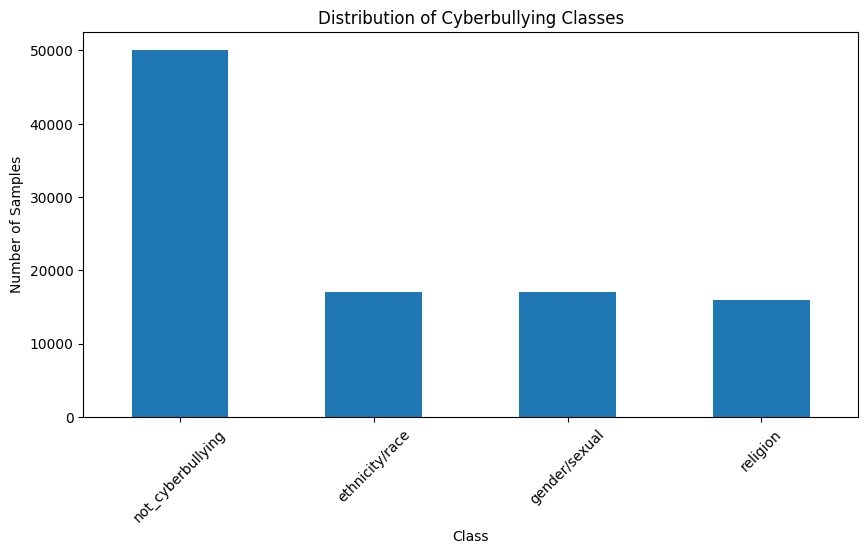

In [11]:
plt.figure(figsize=(10, 5))

df["label"].value_counts().plot(kind="bar")

plt.title("Distribution of Cyberbullying Classes")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

In [12]:
df["text_length"] = df["text"].apply(len)

df[["text", "label", "text_length"]].head()

,text,label,text_length
0,@ZubearSays Any real nigga isn't letting this ...,ethnicity/race,53
1,@MoradoSkittle @prolifejewess @DAConsult @Kell...,not_cyberbullying,162
2,"the only thing i wish, i wish a nigga would",ethnicity/race,43
3,You saudias are not friends of Muslim idiots c...,religion,61
4,@JaydenT2399 @TractorLaw @holmes_gael @erconge...,religion,324


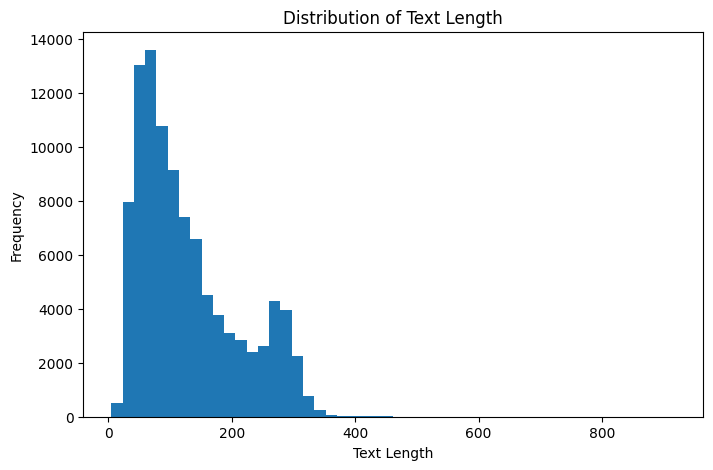

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["text_length"], bins=50)

plt.title("Distribution of Text Length")
plt.xlabel("Text Length")
plt.ylabel("Frequency")

plt.show()

# **Preprocessing**

In [14]:
texts = df["text"].astype(str)
labels = df["label"]

In [15]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(labels)

print(label_encoder.classes_)

['ethnicity/race' 'gender/sexual' 'not_cyberbullying' 'religion']


In [16]:
print(encoded_labels[:20])

[0 2 0 3 3 0 2 3 0 2 2 0 0 2 2 3 2 2 0 2]


In [17]:
num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)

Number of classes: 4


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    encoded_labels,
    test_size=0.20,
    random_state=42,
    stratify=encoded_labels
)

In [19]:
def tokenize(text):
    return text.lower().split()

In [20]:
print(tokenize(X_train.iloc[0]))

['jaehyun', 'serving', 'perfect', 'tumblr', 'beef', 'soft', 'launch', 'pics', 'pls', "he's", 'too', 'good', 'at', 'these', '🫠', 'https://t.co/osr685m5lj']


In [21]:
word_counts = {}

for text in X_train:
    for word in tokenize(text):
        word_counts[word] = word_counts.get(word, 0) + 1

In [22]:
print("Unique words:", len(word_counts))

Unique words: 206419


In [23]:
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word in word_counts:
    vocab[word] = len(vocab)

In [24]:
print("Vocabulary size:", len(vocab))

Vocabulary size: 206421


In [25]:
def encode_text(text):
    tokens = tokenize(text)

    encoded = []

    for word in tokens:
        if word in vocab:
            encoded.append(vocab[word])
        else:
            encoded.append(vocab["<UNK>"])

    return encoded

In [26]:
print(encode_text(X_train.iloc[0]))

[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


In [27]:
text_lengths = []

for text in X_train:
    text_lengths.append(len(tokenize(text)))

print("Average length:", np.mean(text_lengths))
print("Maximum length:", np.max(text_lengths))

Average length: 21.32855785578558
Maximum length: 81


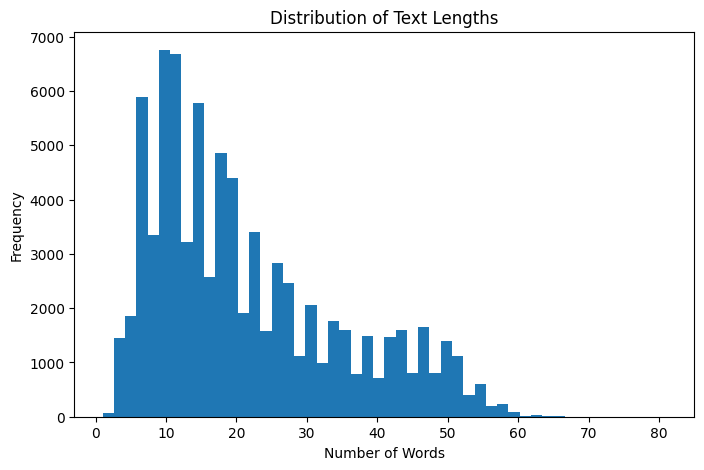

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(text_lengths, bins=50)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Text Lengths")

plt.show()

In [29]:
MAX_LEN = 50
def pad_sequence(sequence, max_len=MAX_LEN):

    if len(sequence) > max_len:
        sequence = sequence[:max_len]

    while len(sequence) < max_len:
        sequence.append(vocab["<PAD>"])

    return sequence

In [30]:
sample = encode_text(X_train.iloc[0])

print("Before padding:", len(sample))

sample = pad_sequence(sample)

print("After padding:", len(sample))

Before padding: 16
After padding: 50


In [31]:
class CyberbullyingDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = self.texts.iloc[index]
        label = self.labels[index]

        encoded = encode_text(text)
        encoded = pad_sequence(encoded)

        return torch.tensor(encoded, dtype=torch.long), torch.tensor(label, dtype=torch.long)

In [32]:
train_dataset = CyberbullyingDataset(X_train, y_train)

test_dataset = CyberbullyingDataset(X_test, y_test)

In [33]:
text_sample, label_sample = train_dataset[0]

print(text_sample)
print(label_sample)

tensor([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])
tensor(2)


In [34]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [35]:
texts_batch, labels_batch = next(iter(train_loader))

print("Text batch shape:", texts_batch.shape)
print("Label batch shape:", labels_batch.shape)

Text batch shape: torch.Size([64, 50])
Label batch shape: torch.Size([64])


In [36]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


# **LSTM**

In [37]:
class SentimentLSTM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        output, (hidden, cell) = self.lstm(x)

        hidden = hidden[-1]

        output = self.fc(hidden)

        return output

In [38]:
VOCAB_SIZE = len(vocab)

EMBEDDING_DIM = 64

HIDDEN_DIM = 128

model = SentimentLSTM(
    VOCAB_SIZE,
    EMBEDDING_DIM,
    HIDDEN_DIM,
    num_classes
)

model = model.to(device)

print(model)

SentimentLSTM(
  (embedding): Embedding(206421, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=4, bias=True)
)


In [39]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [40]:
EPOCHS = 5

train_losses = []
train_accuracies = []

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for texts, labels in train_loader:

        texts = texts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = total_loss / len(train_loader)

    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch 1/5 Loss: 0.7043 Accuracy: 74.60%
Epoch 2/5 Loss: 0.3172 Accuracy: 89.93%
Epoch 3/5 Loss: 0.1896 Accuracy: 94.55%
Epoch 4/5 Loss: 0.0872 Accuracy: 97.63%
Epoch 5/5 Loss: 0.0517 Accuracy: 98.62%


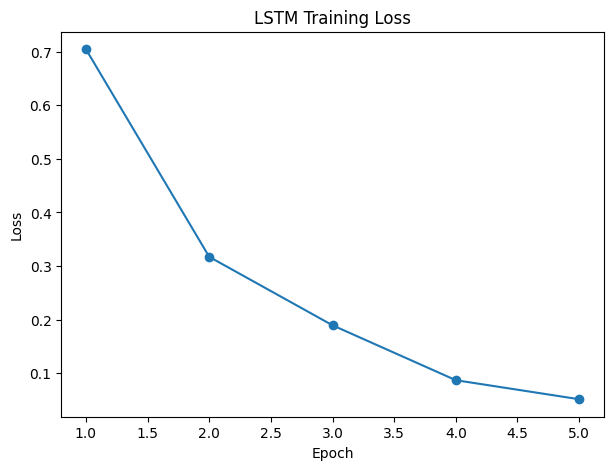

In [41]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training Loss")

plt.show()


# **Evaluate**

In [42]:
model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(device)
        labels = labels.to(device)

        outputs = model(texts)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())

        all_labels.extend(labels.cpu().numpy())

        all_probabilities.extend(probabilities.cpu().numpy())

In [43]:
all_predictions = np.array(all_predictions)

all_labels = np.array(all_labels)

all_probabilities = np.array(all_probabilities)

In [44]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("Test Accuracy:", accuracy * 100)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("Precision:", precision)
recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("Recall:", recall)
f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("F1 Score:", f1)

Test Accuracy: 97.76477647764776
Precision: 0.974849293564306
Recall: 0.9740583121804068
F1 Score: 0.9744405952321858


In [45]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[3299   26   44   31]
 [  23 3303   59   15]
 [  22   56 9848   74]
 [  13   17   67 3101]]


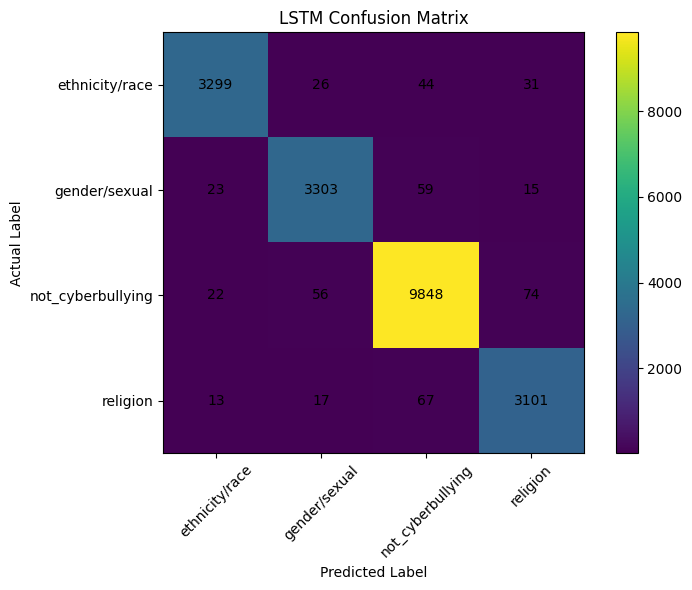

In [53]:
plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Confusion Matrix")

plt.colorbar()

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=45
)

plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

# Add numbers inside each box
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [47]:
auc_roc = roc_auc_score(
    all_labels,
    all_probabilities,
    multi_class="ovr",
    average="macro"
)

print("Macro AUC-ROC:", auc_roc)

Macro AUC-ROC: 0.9967891565624313


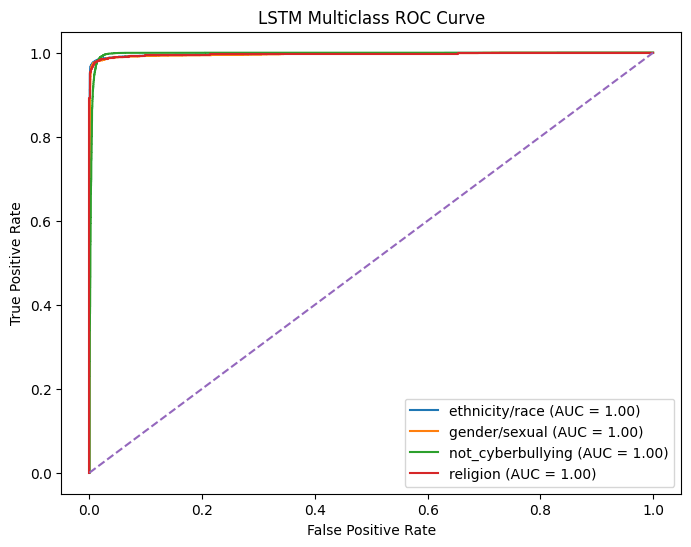

In [48]:
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    all_labels,
    classes=range(num_classes)
)

plt.figure(figsize=(8, 6))

for i in range(num_classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        all_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{label_encoder.classes_[i]} (AUC = {roc_auc:.2f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("LSTM Multiclass ROC Curve")

plt.legend()

plt.show()

In [49]:
def predict_text(text):

    model.eval()

    encoded = encode_text(text)

    encoded = pad_sequence(encoded)

    input_tensor = torch.tensor(
        encoded,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        prediction = torch.argmax(
            probabilities,
            dim=1
        ).item()

    print("Text:", text)

    print(
        "Predicted class:",
        label_encoder.classes_[prediction]
    )

    print(
        "Confidence:",
        probabilities[0][prediction].item()
    )

# **Result**

In [50]:
predict_text(
    "You are a wonderful person and I hope you have a great day"
)

Text: You are a wonderful person and I hope you have a great day
Predicted class: not_cyberbullying
Confidence: 0.9821048378944397


In [51]:
predict_text(
    "@chromiephobical I don’t want you nigga"
)

Text: @chromiephobical I don’t want you nigga
Predicted class: ethnicity/race
Confidence: 0.9991218447685242


In [52]:
predict_text(
    " @Linaya_Bradford Me bitch alwayse"
)

Text:  @Linaya_Bradford Me bitch alwayse
Predicted class: gender/sexual
Confidence: 0.9979318380355835
